In [ ]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import export_graphviz
from IPython.display import Image
import pydotplus

In [ ]:
data=pd.read_excel('/content/Dataset#1.xlsx')
data

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10,Feature11,Feature12,Feature13,Feature14,Feature15,Feature16,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


In [ ]:
data.describe() # Display the statistical description of the data

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10,Feature11,Feature12,Feature13,Feature14,Feature15,Feature16
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [ ]:
data.info() # Summerize the data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature1   13611 non-null  int64  
 1   Feature2   13611 non-null  float64
 2   Feature3   13611 non-null  float64
 3   Feature4   13611 non-null  float64
 4   Feature5   13611 non-null  float64
 5   Feature6   13611 non-null  float64
 6   Feature7   13611 non-null  int64  
 7   Feature8   13611 non-null  float64
 8   Feature9   13611 non-null  float64
 9   Feature10  13611 non-null  float64
 10  Feature11  13611 non-null  float64
 11  Feature12  13611 non-null  float64
 12  Feature13  13611 non-null  float64
 13  Feature14  13611 non-null  float64
 14  Feature15  13611 non-null  float64
 15  Feature16  13611 non-null  float64
 16  Class      13611 non-null  object 
dtypes: float64(14), int64(2), object(1)
memory usage: 1.8+ MB


<ipython-input-4-f63cf9fab082>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(data.corr())


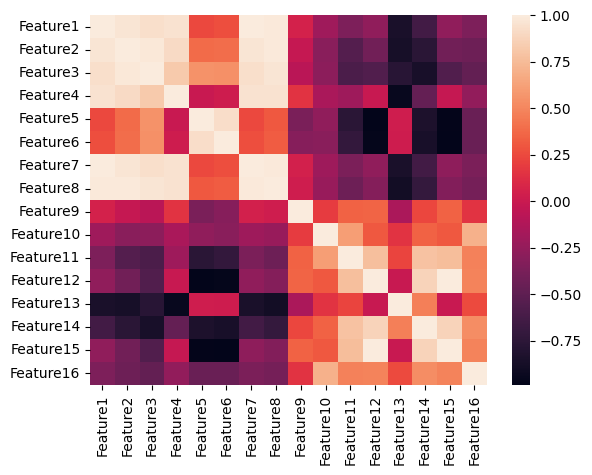

In [ ]:
# Plot the heatmap for the correlation of the features
sns.heatmap(data.corr())
plt.show()

array([[<Axes: title={'center': 'Feature1'}>,
        <Axes: title={'center': 'Feature2'}>,
        <Axes: title={'center': 'Feature3'}>,
        <Axes: title={'center': 'Feature4'}>],
       [<Axes: title={'center': 'Feature5'}>,
        <Axes: title={'center': 'Feature6'}>,
        <Axes: title={'center': 'Feature7'}>,
        <Axes: title={'center': 'Feature8'}>],
       [<Axes: title={'center': 'Feature9'}>,
        <Axes: title={'center': 'Feature10'}>,
        <Axes: title={'center': 'Feature11'}>,
        <Axes: title={'center': 'Feature12'}>],
       [<Axes: title={'center': 'Feature13'}>,
        <Axes: title={'center': 'Feature14'}>,
        <Axes: title={'center': 'Feature15'}>,
        <Axes: title={'center': 'Feature16'}>]], dtype=object)

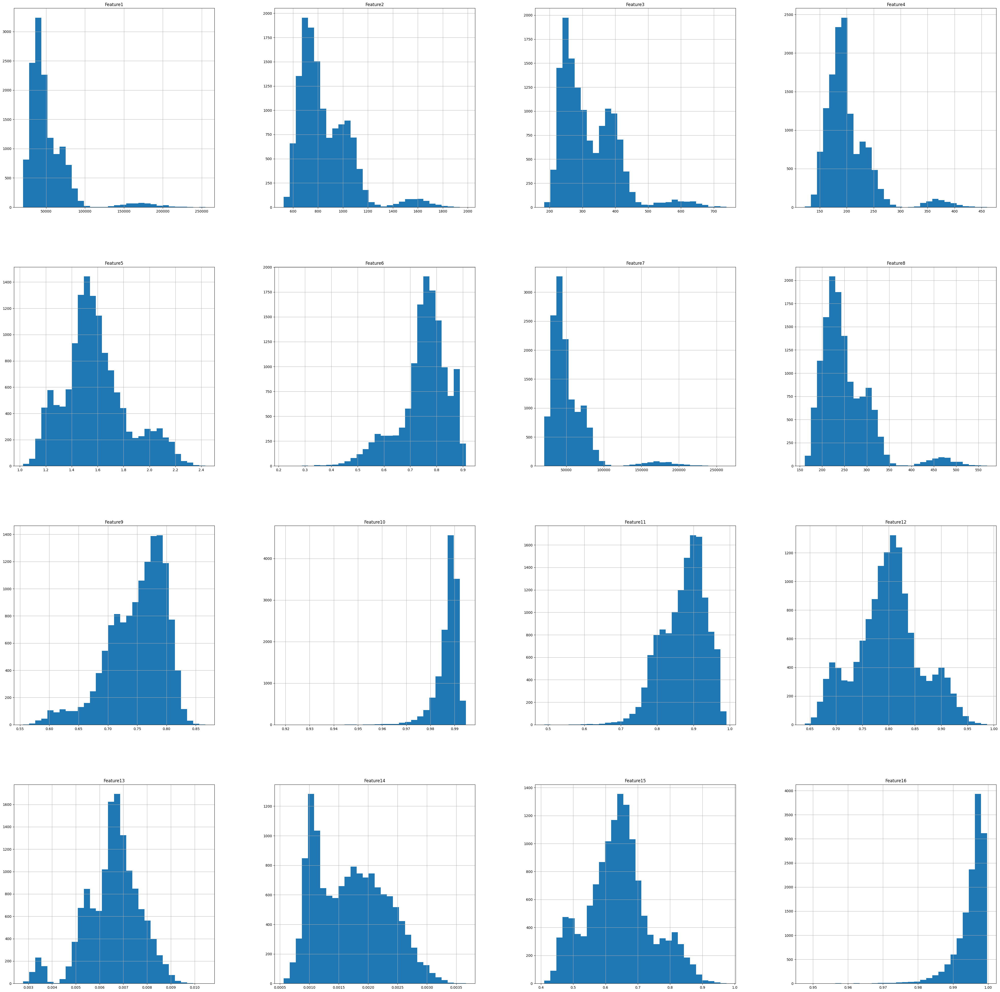

In [ ]:
data.hist(bins=30,figsize=(50,50)) # Plot the distribution of the features

<Axes: xlabel='Class', ylabel='count'>

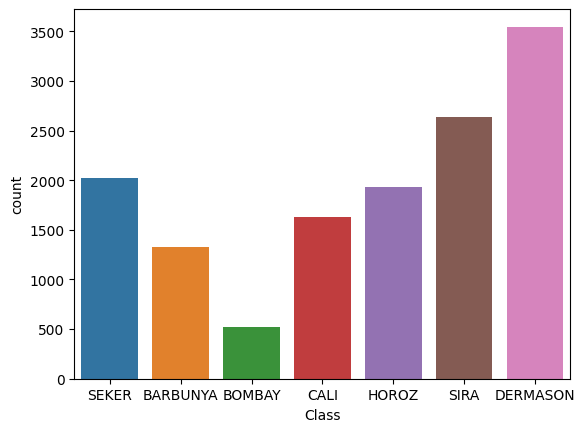

In [ ]:
sns.countplot(data,x='Class') # Plot the count of each class in the target column

In [ ]:
data['Class'].value_counts() # Display the counts of each class

DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: Class, dtype: int64

<font color='sky blue'>**REMOVING DUPLICATES**

In [ ]:
data.drop_duplicates(inplace=True)
data

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10,Feature11,Feature12,Feature13,Feature14,Feature15,Feature16,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


<font color='SKY BLUE'>**UPSAMPLING FOR IMPALANCE PROBLEM**

<font color='SKY BLUE'>**STANDARDIZATION**

In [ ]:
# Standardize the data for better performance and for the PCA process
sc = StandardScaler()
for col in data.columns:
  if not col=='Class':
    data[col] = sc.fit_transform(data[[col]])
data

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10,Feature11,Feature12,Feature13,Feature14,Feature15,Feature16,Class
0,-0.838800,-1.139663,-1.301976,-0.632111,-1.565363,-2.182833,-0.839489,-1.060491,0.287981,0.366476,1.420346,1.838628,0.681918,2.398280,1.924811,0.838679,SEKER
1,-0.827266,-1.010529,-1.391169,-0.435758,-1.972460,-3.685504,-0.824175,-1.041410,0.697598,-0.465886,0.224987,2.497622,0.369552,3.097471,2.691446,0.771141,SEKER
2,-0.805287,-1.075303,-1.247807,-0.586775,-1.514305,-2.042229,-0.806818,-1.005357,0.577958,0.517614,1.248979,1.764053,0.604373,2.231086,1.840150,0.917418,SEKER
3,-0.783920,-0.973894,-1.274241,-0.440595,-1.742960,-2.740196,-0.772170,-0.970686,0.671302,-2.248692,0.509588,2.082211,0.403254,2.511258,2.204306,-0.202373,SEKER
4,-0.779429,-1.093821,-1.375750,-0.268281,-2.121534,-4.535823,-0.782457,-0.963445,0.475476,0.804605,1.872434,2.768598,0.120215,3.267675,3.016333,0.940406,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,-0.372608,-0.443833,-0.363307,-0.364498,-0.115589,0.159896,-0.377306,-0.362838,-0.720413,0.683738,0.722866,0.024619,0.263164,0.050155,-0.013718,0.760769,DERMASON
13607,-0.372472,-0.454065,-0.446579,-0.258650,-0.426673,-0.159087,-0.377775,-0.362653,1.024032,0.774149,0.813994,0.356320,0.112342,0.279797,0.321924,0.722442,DERMASON
13608,-0.371179,-0.445579,-0.447004,-0.248110,-0.442403,-0.176913,-0.375262,-0.360891,-0.406580,0.590730,0.753526,0.364089,0.106237,0.283888,0.329887,0.388529,DERMASON
13609,-0.370907,-0.424817,-0.425529,-0.268360,-0.374124,-0.100814,-0.371978,-0.360520,-0.908104,0.142083,0.576435,0.278309,0.143819,0.223018,0.242229,0.033115,DERMASON


<font color='SKY BLUE'>**ONEHOT ENCODING**

In [ ]:
# Onehot encoding for the target column to convert to numercal data
encoded_data=pd.get_dummies(data,'Class')
encoded_data # The data will become multilabeled

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10,...,Feature14,Feature15,Feature16,Class_BARBUNYA,Class_BOMBAY,Class_CALI,Class_DERMASON,Class_HOROZ,Class_SEKER,Class_SIRA
0,-0.838800,-1.139663,-1.301976,-0.632111,-1.565363,-2.182833,-0.839489,-1.060491,0.287981,0.366476,...,2.398280,1.924811,0.838679,0,0,0,0,0,1,0
1,-0.827266,-1.010529,-1.391169,-0.435758,-1.972460,-3.685504,-0.824175,-1.041410,0.697598,-0.465886,...,3.097471,2.691446,0.771141,0,0,0,0,0,1,0
2,-0.805287,-1.075303,-1.247807,-0.586775,-1.514305,-2.042229,-0.806818,-1.005357,0.577958,0.517614,...,2.231086,1.840150,0.917418,0,0,0,0,0,1,0
3,-0.783920,-0.973894,-1.274241,-0.440595,-1.742960,-2.740196,-0.772170,-0.970686,0.671302,-2.248692,...,2.511258,2.204306,-0.202373,0,0,0,0,0,1,0
4,-0.779429,-1.093821,-1.375750,-0.268281,-2.121534,-4.535823,-0.782457,-0.963445,0.475476,0.804605,...,3.267675,3.016333,0.940406,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,-0.372608,-0.443833,-0.363307,-0.364498,-0.115589,0.159896,-0.377306,-0.362838,-0.720413,0.683738,...,0.050155,-0.013718,0.760769,0,0,0,1,0,0,0
13607,-0.372472,-0.454065,-0.446579,-0.258650,-0.426673,-0.159087,-0.377775,-0.362653,1.024032,0.774149,...,0.279797,0.321924,0.722442,0,0,0,1,0,0,0
13608,-0.371179,-0.445579,-0.447004,-0.248110,-0.442403,-0.176913,-0.375262,-0.360891,-0.406580,0.590730,...,0.283888,0.329887,0.388529,0,0,0,1,0,0,0
13609,-0.370907,-0.424817,-0.425529,-0.268360,-0.374124,-0.100814,-0.371978,-0.360520,-0.908104,0.142083,...,0.223018,0.242229,0.033115,0,0,0,1,0,0,0


<font color='SKY BLUE'>**DIMENSIONALITY REDUCTION USING PCA**

In [ ]:
pca = PCA(n_components=8,svd_solver="randomized") # Reduce the features to the first 8 principle components
X_reduced = pca.fit_transform(encoded_data.iloc[:,:16]) # Feature columns

In [ ]:
y=encoded_data.iloc[:,16:] # Target column
y

,Class_BARBUNYA,Class_BOMBAY,Class_CALI,Class_DERMASON,Class_HOROZ,Class_SEKER,Class_SIRA
0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0
2,0,0,0,0,0,1,0
3,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...
13606,0,0,0,1,0,0,0
13607,0,0,0,1,0,0,0
13608,0,0,0,1,0,0,0
13609,0,0,0,1,0,0,0


In [ ]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X_reduced, y, test_size=0.2, random_state=42,stratify=y) # Split the data to train test
X_train, X_val, y_train, y_val = train_test_split(Xtrain, ytrain, test_size=0.1, random_state=42,stratify=ytrain) # From the training set we will again split it to train validation

# <font color='hotpink'>**MODEL1: KNN**

<font color='SKY BLUE'>**VALIDATION PHASE**

In [ ]:
knn = KNeighborsClassifier(n_neighbors= 10) # KNN classifier
knn.fit(X_train, y_train) # Train the data using the second training set
# Evaluate the data in the validation phase
y_valpred = knn.predict(X_val)
acc=accuracy_score(y_val, y_valpred)
f1=f1_score(y_val, y_valpred,average='macro')
print('Accuracy = ', acc*100)
print('F1_score=', f1*100)

Accuracy =  92.89303661162958
F1_score= 93.88978529212899


<font color='SKY BLUE'>**HYPERPARAMETER TUNING**

In [ ]:
# NOTE : Will take a while to run
# Using GridSearch to choose the best hyperparameters
hparam={'n_neighbors':[5,10,30,50,150]}
cv=GridSearchCV(knn,hparam,scoring='accuracy')
cv.fit(X_train,y_train)
bestparam=cv.best_params_
knn.set_params(n_neighbors=bestparam['n_neighbors']) # Set the new parameters to the model
knn.fit(Xtrain, ytrain) # Train the model with the actual training set

KNeighborsClassifier()

<font color='SKY BLUE'>**TESTING PHASE (MODEL EVALUATION)**

In [ ]:
# Evaluate the model (unseen data)
y_pred = knn.predict(Xtest)
acc_knn=accuracy_score(ytest, y_pred)
f1_knn=f1_score(ytest, y_pred,average='macro')
print('Accuracy = ', acc_knn*100)
print('F1_score=', f1_knn*100)

Accuracy =  95.51981619758759
F1_score= 95.60555999221363


<font color='SKY BLUE'>**VALIDATION PHASE**

In [ ]:
# DecisionTree Classifier
clf = DecisionTreeClassifier( max_depth=40,
    min_samples_split=22,
    min_samples_leaf=4,
    max_features=None ,
    random_state=42)
clf.fit(X_train, y_train) # Train the data using the second training set
# Evaluate the data in the validation phase
y_pred = clf.predict(X_val)
accuracy= accuracy_score(y_val, y_pred)
f1_DT=f1_score(y_val,y_pred,average='macro')
print(f"Accuracy: {accuracy*100}")
print('F1_score: ',f1_DT*100)

Accuracy: 93.82627422828428
F1_score:  94.7782081410611


<font color='SKY BLUE'>**HYPERPARAMETER TUNING**

In [ ]:
# NOTE : It will take several minutes to run
# Using GridSearch to choose the best hyperparameters
hparam={'max_depth':[10,20,40,55],'min_samples_split':[5,10,20,30,50],'min_samples_leaf':[4,10,20,30,50]}
cv=GridSearchCV(clf,hparam,scoring='accuracy')
cv.fit(X_train,y_train)
bestparam=cv.best_params_
clf.set_params(max_depth=bestparam['max_depth'],min_samples_split=bestparam['min_samples_split'],min_samples_leaf=bestparam['min_samples_leaf']) # Set the new parameters to the model
clf.fit(Xtrain, ytrain) # Train the model with the actual training set

DecisionTreeClassifier(max_depth=40, min_samples_leaf=4, min_samples_split=5,
                       random_state=42)

<font color='SKY BLUE'>**TESTING PHASE (MODEL EVALUATION)**

In [ ]:
# Model evaluation (unseen data)
y_pred = clf.predict(Xtest)
accuracy_DT = accuracy_score(ytest, y_pred)
f1_DT=f1_score(ytest,y_pred,average='macro')
print(f"Accuracy: {accuracy_DT*100}")
print('F1_score: ',f1_DT*100)

Accuracy: 95.59161401493395
F1_score:  96.15310704921568


<font color='sky blue'>**DecisionTree Graph**

In [ ]:
dot_data = export_graphviz(clf,
                           feature_names=pd.DataFrame(X_reduced).columns,
                           class_names=y,
                           filled=True, rounded=True, special_characters=True)

graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

dot: graph is too large for cairo-renderer bitmaps. Scaling by 0.801875 to fit



<font color='SKY BLUE'>**VALIDATION PHASE**

In [ ]:
# RandomForest classifier
rf_clf = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=40,
    min_samples_split=10,
    min_samples_leaf=15,
    max_features='sqrt',
    bootstrap=True,
)
rf_clf.fit(X_train, y_train) # Train the data using the second training set
# Evaluate the data in the validation phase
y_pred = rf_clf.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
f1_RF=f1_score(y_val,y_pred,average='macro')
print(f"Accuracy: {accuracy*100}")
print('F1_score: ',f1_RF*100)

Accuracy: 92.46231155778895
F1_score:  94.36680779602858


<font color='SKY BLUE'>**HYPERPARAMETER TUNING**

In [ ]:
# NOTE : Please avoid running this cell because it will take a huge amount of time to run
# Using GridSearch to choose the best hyperparameters
hparam={'max_depth':[10,20,40,55],'min_samples_split':[2,5,10,20,30,50],'min_samples_leaf':[2,4,10,20,30,50]}
cv=GridSearchCV(rf_clf,hparam,scoring='accuracy')
cv.fit(X_train,y_train)
bestparam=cv.best_params_
rf_clf.set_params(max_depth=bestparam['max_depth'],min_samples_split=bestparam['min_samples_split'],min_samples_leaf=bestparam['min_samples_leaf']) # Set the new parameters to the model

In [ ]:
rf_clf.fit(Xtrain, ytrain) # Train the model with the actual training set

RandomForestClassifier(max_depth=40, min_samples_leaf=2, random_state=42)

<font color='SKY BLUE'>**TESTING PHASE (MODEL EVALUATION)**

In [ ]:
# Evaluate the model (unseen data)
y_pred = rf_clf.predict(Xtest)
accuracy_RF = accuracy_score(ytest, y_pred)
f1_RF=f1_score(ytest,y_pred,average='macro')
print(f"Accuracy: {accuracy_RF*100}")
print('F1_score: ',f1_RF*100)

Accuracy: 97.80298678920161
F1_score:  97.97441501855927


<font color='sky blue'>**RandomForest Visualization**

In [ ]:
tree_index = 0
tree = rf_clf.estimators_[tree_index]
dot_data = export_graphviz(tree,
                           feature_names=list(range(1, X_reduced.shape[1] + 1)),
                           class_names=list(map(str, np.unique(y))),
                           filled=True, rounded=True, special_characters=True)

graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

dot: graph is too large for cairo-renderer bitmaps. Scaling by 0.558363 to fit



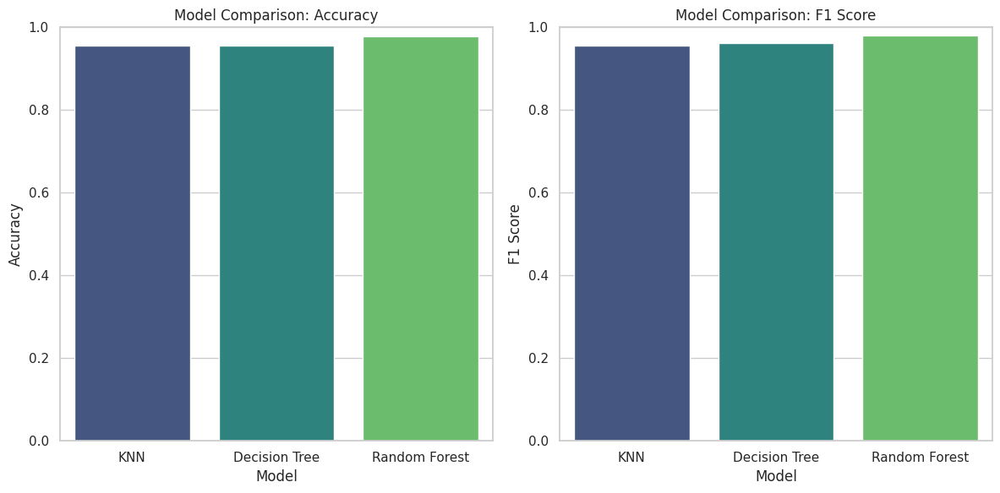

In [ ]:
models = ['KNN', 'Decision Tree', 'Random Forest']
# Our Results
accuracy_scores = [acc_knn, accuracy_DT, accuracy_RF]
f1_scores = [f1_knn, f1_DT, f1_RF]
df = pd.DataFrame({'Model': models, 'Accuracy': accuracy_scores, 'F1 Score': f1_scores})
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.barplot(x='Model', y='Accuracy', data=df, palette="viridis")
plt.title('Model Comparison: Accuracy')
plt.ylim(0, 1)
plt.subplot(1, 2, 2)
sns.barplot(x='Model', y='F1 Score', data=df, palette="viridis")
plt.title('Model Comparison: F1 Score')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()